# Introduction

This notebook conducts the investigation of which projection algorithm and distance measure will be used for the final user interface.

## Preperation

We start off by: 
* loading the dataset that is subject for Dimensionality Reduction (DR),
* loading the yaml file classifying the attribute types in the dataset,
* installing the necessary depencencies in order to access DR libraries,
* selecting which student attributes (columns) to include in the DR,
* and select which columns that should be standardized.

In [19]:
import pandas as pd
from yaml import SafeLoader, load

from resources.paths import DATA_ROOT_PROCESSED


In [20]:
df = pd.read_csv(DATA_ROOT_PROCESSED / "student_dropout_dataset.csv")
with open(DATA_ROOT_PROCESSED / "attribute_types.yaml") as f:
    attribute_types = load(f, Loader=SafeLoader)


In [21]:
display(df)
display(attribute_types)

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Scholarship holder,Age at enrollment,International,Curricular units (credited),Curricular units (enrolled),Curricular units (evaluations),Curricular units (approved),Curricular units (grade),Curricular units (without evaluations),Graduation status
0,1,17,5,171,1,1,122.0,1,19,12,...,0,20,0,0,0,0,0,0.000000,0,0
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,19,0,0,6,6,6,14.000000,0,2
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,19,0,0,6,0,0,0.000000,0,0
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,20,0,0,6,8,6,13.428571,0,2
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,45,0,0,6,9,5,12.333333,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,19,0,0,6,7,5,13.600000,0,2
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,18,1,0,6,6,6,12.000000,0,0
4421,1,1,1,9500,1,1,154.0,1,37,37,...,1,30,0,0,7,8,7,14.912500,0,0
4422,1,1,1,9147,1,1,180.0,1,37,37,...,1,20,0,0,5,5,5,13.800000,0,2


{'binary': ['Displaced',
  'Educational special needs',
  'Debtor',
  'Tuition fees up to date',
  'Gender',
  'Scholarship holder',
  'International'],
 'nominal': ['Marital Status',
  'Application mode',
  'Course',
  'Daytime/evening attendance',
  'Previous qualification',
  'Nationality',
  "Mother's qualification",
  "Father's qualification",
  "Mother's occupation",
  "Father's occupation",
  'Graduation status'],
 'numerical': ['Admission grade',
  'Age at enrollment',
  'Previous qualification (grade)',
  'Curricular units (credited)',
  'Curricular units (enrolled)',
  'Curricular units (evaluations)',
  'Curricular units (approved)',
  'Curricular units (grade)',
  'Curricular units (without evaluations)'],
 'ordinal': ['Application order']}

In [22]:
%pip install "scikit-learn>=1.9.1"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
%pip install "umap-learn>=0.6.0"


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Selecting columns

The columns are selected based on the analytical goal as documented in the report: "...to enable users to discover patterns and potential associations between academic outcomes and multiple student attributes within a latent 2D space.". With academic outcomes, we refer to the possible values in the 'Graduation status' attribute in the dataset. Considering this goal, we conclude that all curricular unit attributes, age, admission grade, and previous qualification grade attributes should be included in the DR as these may be highly associated with academic outcome.

In [ ]:
columns_to_include = attribute_types["numerical"] # mentioned attributes in previous cell are all contained in the numerical list

Further...

In [24]:
columns_to_include = attribute_types["numerical"] + attribute_types["binary"] + attribute_types["ordinal"]
df_included = df[columns_to_include]

In [25]:
print("Columns to include in the DM:")
for column in columns_to_include:
    print(f"\t{column}")

Columns to include in the DM:
	Admission grade
	Age at enrollment
	Previous qualification (grade)
	Curricular units (credited)
	Curricular units (enrolled)
	Curricular units (evaluations)
	Curricular units (approved)
	Curricular units (grade)
	Curricular units (without evaluations)
	Displaced
	Educational special needs
	Debtor
	Tuition fees up to date
	Gender
	Scholarship holder
	International
	Application order


### Selecting columns to standardize

In [26]:
columns_to_standardize = attribute_types["numerical"] + attribute_types["ordinal"]

In [27]:
print("Columns to standardize:")
for column in columns_to_standardize:
    print(f"\t{column}")

Columns to standardize:
	Admission grade
	Age at enrollment
	Previous qualification (grade)
	Curricular units (credited)
	Curricular units (enrolled)
	Curricular units (evaluations)
	Curricular units (approved)
	Curricular units (grade)
	Curricular units (without evaluations)
	Application order


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_to_standardize = df[columns_to_standardize]
scaled_data = scaler.fit_transform(data_to_standardize)
df_scaled = df_included.copy()
df_scaled[columns_to_standardize] = scaled_data

In [29]:
df_scaled.head(10)

,Admission grade,Age at enrollment,Previous qualification (grade),Curricular units (credited),Curricular units (enrolled),Curricular units (evaluations),Curricular units (approved),Curricular units (grade),Curricular units (without evaluations),Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,International,Application order
0,0.022229,-0.430363,-0.804841,-0.300813,-2.528560,-1.986068,-1.521257,-2.197102,-0.199273,1,0,0,1,1,0,0,2.490896
1,1.071926,-0.562168,2.076819,-0.300813,-0.109105,-0.550192,0.418050,0.693599,-0.199273,1,0,0,0,1,0,0,-0.554068
2,-0.150419,-0.562168,-0.804841,-0.300813,-0.109105,-1.986068,-1.521257,-2.197102,-0.199273,1,0,0,0,1,0,0,2.490896
3,-0.509526,-0.430363,-0.804841,-0.300813,-0.109105,-0.071567,0.418050,0.575611,-0.199273,1,0,0,1,0,0,0,0.207173
4,1.002867,2.864765,-2.473171,-0.300813,-0.109105,0.167746,0.094832,0.349468,-0.199273,0,0,0,1,0,0,0,-0.554068
5,-0.841009,3.523791,0.036907,-0.300813,-0.512348,0.407059,0.094832,0.251144,-0.199273,0,0,1,1,1,0,0,-0.554068
6,0.098194,-0.693973,0.711822,-0.300813,0.294137,0.167746,0.741268,0.549064,-0.199273,1,0,0,1,0,1,0,-0.554068
7,-0.958410,-0.166753,-1.032341,-0.300813,-0.512348,-0.789505,-1.521257,-2.197102,-0.199273,1,0,0,0,1,0,0,1.729655
8,0.160347,-0.298558,0.332656,-0.300813,-0.109105,-0.071567,0.418050,0.667789,-0.199273,0,0,0,1,0,1,1,0.968414
9,-0.274725,-0.693973,0.408490,-0.300813,-0.109105,0.167746,0.094832,0.156754,-0.199273,1,0,1,0,0,0,0,-0.554068


## Projection algorithms

In [30]:
from sklearn.manifold import MDS, TSNE
from umap import UMAP

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [31]:
n_components = 2
random_state = 42

tsne = TSNE(n_components=n_components, random_state=random_state)
mds = MDS(n_components=n_components, random_state=random_state)
umap = UMAP(n_components=n_components, random_state=random_state)

In [32]:
tsne_fit = tsne.fit_transform(df_scaled)

In [33]:
mds_fit = mds.fit_transform(df_scaled)

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(


In [34]:
umap_fit = umap.fit_transform(df_scaled)

/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Users/pettergustafsson/study/4DT912-advanced-info-viz/4dt912-project/research/.venv/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


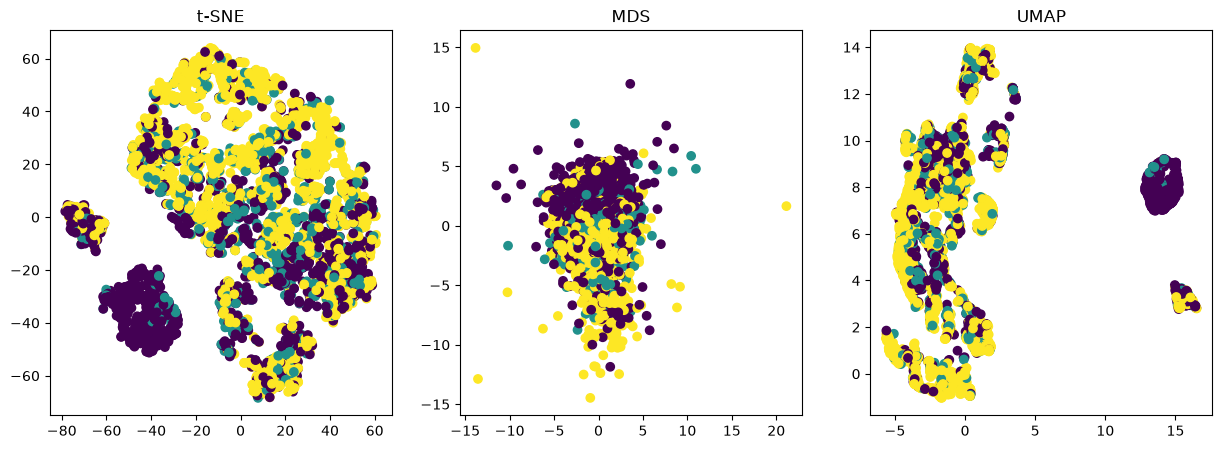

In [35]:
# Visualize the projections using PCA, MDS, and UMAP using scatterplots and color by Graduation status
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].scatter(tsne_fit[:, 0], tsne_fit[:, 1], c=df['Graduation status'])
axes[0].set_title("t-SNE")
axes[1].scatter(mds_fit[:, 0], mds_fit[:, 1], c=df['Graduation status'])
axes[1].set_title("MDS")
axes[2].scatter(umap_fit[:, 0], umap_fit[:, 1], c=df['Graduation status'])
axes[2].set_title("UMAP")
plt.show()

## Distance metrics

## Comparative evaluation

## Technique selection